# 회귀 · 이동 시간 실전 연습

공개 응시 후기의 작업 유형을 바탕으로 만든 **창작 14문항**입니다. 실제 기출 원문이 아닙니다. 문제에 지정한 변수명·조건을 지키세요. 각 문제의 설명은 필요한 용도를, 접힌 힌트는 함수 이름을 알려줍니다. 정답은 별도 파일입니다.

학습/검증 **2분할**을 사용합니다. 13~14번은 딥러닝 집중 문제입니다. 기준 모델 비교 등 추가 이해용 문항은 없습니다.

정답 travel_minutes: 이동 시간(분). distance_km=거리, traffic_score=혼잡도, stops=정차 횟수, rain=비 여부.

## 01. 라이브러리

데이터 처리와 그래프 작성에 사용할 pandas, NumPy, matplotlib.pyplot, seaborn을 각각 pd, np, plt, sns로 불러오세요.

<details><summary>힌트 보기</summary>

import … as …

</details>

In [26]:
# 여기에 답안코드를 작성하고 실행하세요.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 02. 데이터 읽기

`02_travel.csv`를 읽어 data에 저장하고 처음 5행을 출력하세요.

<details><summary>힌트 보기</summary>

pd.read_csv()

</details>

In [27]:
# 여기에 답안코드를 작성하고 실행하세요.
data = pd.read_csv("02_travel.csv")
data.head(5)

,distance_km,traffic_score,stops,rain,travel_minutes
0,2.82,5.72,1,Yes,16.81
1,39.60,7.31,1,No,95.13
2,25.45,4.15,3,No,60.47
3,7.00,4.44,3,No,30.62
4,16.24,5.09,5,No,44.08


## 03. 데이터 확인

행·열 개수, 자료형, 컬럼별 결측치 수를 확인하세요. 결측치가 가장 많은 컬럼 이름을 answer03에 저장하세요.

<details><summary>힌트 보기</summary>

shape, info(), isnull().sum(), idxmax()

</details>

In [28]:
# 여기에 답안코드를 작성하고 실행하세요.
print(data.shape)
print(data.dtypes)
print(data.isna().sum())

answer03 = "traffic_score"

(1000, 5)
distance_km       float64
traffic_score     float64
stops               int64
rain                  str
travel_minutes    float64
dtype: object
distance_km        0
traffic_score     22
stops              0
rain              12
travel_minutes     0
dtype: int64


## 04. 그룹별 집계

`rain`별 `travel_minutes`의 평균을 계산해 group_result에 저장하고 출력하세요. 그룹 간 차이를 확인하는 작업입니다.

<details><summary>힌트 보기</summary>

groupby()[…].mean()

</details>

In [29]:
# 여기에 답안코드를 작성하고 실행하세요.
group_result = data.groupby("rain")["travel_minutes"].mean()
print(group_result)

rain
No     54.047733
Yes    60.086345
Name: travel_minutes, dtype: float64


## 05. 시각화

seaborn scatterplot으로 distance_km와 travel_minutes의 관계를 그리세요. 제목은 Distance and Time입니다.

<details><summary>힌트 보기</summary>

sns.countplot / sns.scatterplot

</details>

Text(0.5, 1.0, 'Distance and Time')

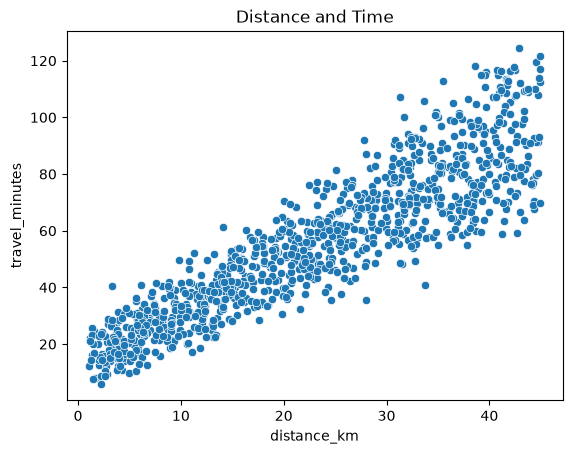

In [30]:
# 여기에 답안코드를 작성하고 실행하세요.
sns.scatterplot(data=data, x="distance_km", y="travel_minutes")
plt.title("Distance and Time")

## 06. 결측치 처리

`traffic_score`의 결측치는 해당 컬럼 중앙값으로, `rain`의 결측치는 최빈값으로 대체하세요. 처리 결과를 data에 반영하고 결측치 수를 확인하세요.

<details><summary>힌트 보기</summary>

fillna(), median(), mode()[0]

</details>

In [31]:
# 여기에 답안코드를 작성하고 실행하세요.
data["traffic_score"] = data["traffic_score"].fillna(data["traffic_score"].median())
data["rain"] = data["rain"].fillna(data["rain"].mode().iloc[0])

print(data.isna().sum())

distance_km       0
traffic_score     0
stops             0
rain              0
travel_minutes    0
dtype: int64


## 07. 범주형 인코딩

`rain`을 pd.get_dummies로 변환해 data_encoded에 저장하세요. dtype=int로 설정하고 나머지 컬럼은 유지하세요.

<details><summary>힌트 보기</summary>

pd.get_dummies(data, columns=[…], dtype=int)

</details>

In [32]:
# 여기에 답안코드를 작성하고 실행하세요.

data_encoded = pd.get_dummies(
    data,
    columns=["rain"],
    dtype=int
)

## 08. 입력과 정답 분리

data_encoded에서 `travel_minutes`을 제외한 입력을 X에, `travel_minutes`을 y에 저장하세요.

<details><summary>힌트 보기</summary>

drop(columns=[…])

</details>

In [33]:
# 여기에 답안코드를 작성하고 실행하세요.
X = data_encoded.drop(columns=["travel_minutes"])
y = data_encoded["travel_minutes"]

## 09. 학습·검증 분할

train_test_split으로 학습 80%, 검증 20%, random_state=42로 분할하세요. 변수는 X_train, X_valid, y_train, y_valid입니다.

<details><summary>힌트 보기</summary>

sklearn.model_selection.train_test_split

</details>

In [34]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

## 10. 스케일링

StandardScaler를 scaler에 생성하세요. 학습 입력은 fit_transform하여 X_train_scaled에, 검증 입력은 transform하여 X_valid_scaled에 저장하세요.

<details><summary>힌트 보기</summary>

sklearn.preprocessing.StandardScaler

</details>

In [35]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

## 11. 머신러닝 학습

RandomForestRegressor를 rf에 생성하세요. n_estimators=100, max_depth=6, random_state=42로 설정하고 X_train, y_train으로 학습하세요. X_valid 예측을 pred_rf에 저장하세요.

<details><summary>힌트 보기</summary>

sklearn.ensemble

</details>

In [36]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=6,
    random_state=42
)

rf.fit(X_train, y_train)

pred_rf = rf.predict(X_valid)

## 12. 머신러닝 평가

MAE, MSE, RMSE, R²를 각각 mae_rf, mse_rf, rmse_rf, r2_rf에 저장해 출력하세요.

<details><summary>힌트 보기</summary>

sklearn.metrics

</details>

In [37]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_rf = mean_absolute_error(y_valid, pred_rf)
mse_rf = mean_squared_error(y_valid, pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_valid, pred_rf)

print(mae_rf, mse_rf, rmse_rf, r2_rf)

4.4075725299689905 30.223386585635026 5.497580066323275 0.9523419394737286


## 13. 딥러닝 구성·학습

다음 조건에 맞춰 model을 구성하고 학습하세요. Dense는 뉴런 층, Dropout은 학습 중 일부 출력을 꺼 과적합을 줄이는 층입니다.

- 입력 특성 수: X_train_scaled.shape[1]
- 은닉층: Dense(32, relu) → Dropout(0.2) → Dense(16, relu)
- 출력층: Dense(1, linear)
- optimizer: adam, loss: mse, metrics: ["mse"]
- estop: EarlyStopping, monitor="val_loss", patience=5
- checkpoint: ModelCheckpoint, 경로="best_02_travel.keras", monitor="val_loss", save_best_only=True
- epochs=30, batch_size=32, 검증 데이터=(X_valid_scaled, y_valid), callbacks=[estop, checkpoint]
- 학습 기록은 history에 저장하세요. 학습 정답은 y_train입니다.

<details><summary>힌트 보기</summary>

tensorflow.keras.models.Sequential, layers.Dense/Dropout, callbacks.EarlyStopping/ModelCheckpoint. model.compile() 후 history = model.fit().

</details>

In [38]:
# 여기에 답안코드를 작성하고 실행하세요.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

model = Sequential([
    Dense(32, activation="relu", input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1, activation="linear")
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mse"]
)

estop = EarlyStopping(
    monitor="val_loss",
    patience=5
)

checkpoint = ModelCheckpoint(
    filepath="best_02_travel.keras",
    monitor="val_loss",
    save_best_only=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_valid_scaled, y_valid),
    callbacks=[estop, checkpoint]
)


Epoch 1/30


c:\Users\LSG\Desktop\AICE\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 3742.1360 - mse: 3742.1360 - val_loss: 3254.1238 - val_mse: 3254.1238
Epoch 2/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3619.8647 - mse: 3619.8647 - val_loss: 3113.3296 - val_mse: 3113.3296
Epoch 3/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3430.4119 - mse: 3430.4119 - val_loss: 2895.8406 - val_mse: 2895.8406
Epoch 4/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3150.5002 - mse: 3150.5002 - val_loss: 2575.8821 - val_mse: 2575.8821
Epoch 5/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2746.0618 - mse: 2746.0618 - val_loss: 2151.6899 - val_mse: 2151.6899
Epoch 6/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2219.8069 - mse: 2219.8069 - val_loss: 1648.8612 - val_mse: 1648.8612
Epoch 7/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1641.5190 - mse: 1641.5190 - val_loss: 1128.0696 - val_mse: 1128.0696
Epoch 8/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1089.9176 - mse: 1089.9176 - val_loss: 665.0806 - val_mse

## 14. 저장 모델 예측·평가·그래프

① 다음 작업을 수행하세요.`best_02_travel.keras`를 load_model로 불러와 best_model에 저장하세요.

② X_valid_scaled 예측 전체를 dl_output에 저장하세요. 출력이 1열이므로 dl_output[:, 0]을 dl_pred에 저장하세요. MAE를 mae_dl에 저장해 출력하세요.

③ history의 mse와 val_mse를 한 그래프에 그리세요. 범례는 mse/val_mse, 제목은 Model MSE, x축은 Epoch, y축은 MSE입니다.

그래프는 이번 학습의 전체 기록이고, 예측은 저장된 최적 모델을 사용합니다.

<details><summary>힌트 보기</summary>

load_model(), predict(), [:, 0], history.history[지표명]

</details>

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
4.783881668472291


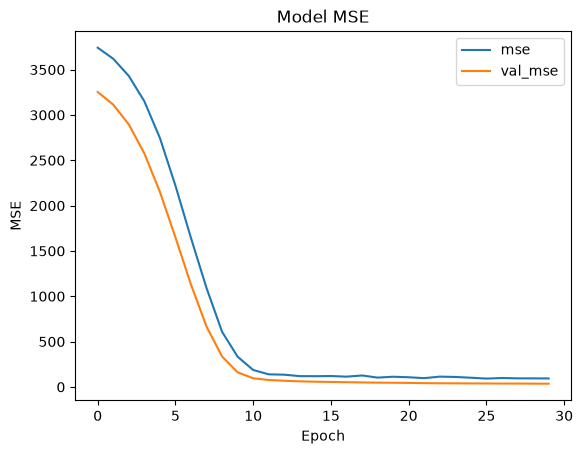

In [39]:
# 여기에 답안코드를 작성하고 실행하세요.
from tensorflow.keras.models import load_model

best_model = load_model("best_02_travel.keras")

dl_output = best_model.predict(X_valid_scaled)
dl_pred = dl_output[:,0]
mae_dl = mean_absolute_error(y_valid, dl_pred)
print(mae_dl)

plt.plot(history.history["mse"], label="mse")
plt.plot(history.history["val_mse"], label="val_mse")

plt.legend()
plt.title("Model MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.show()

참고: 시험 흐름에 맞춰 06~07번 전처리를 분할 전에 지시했습니다. 실무의 엄격한 성능 검증에서는 분할 후 학습 데이터에서 대체값과 인코딩 기준을 정하는 것이 원칙입니다. 이 세트는 시험형 코드 작성 연습입니다.

문항의 출처와 근거 수준은 READ_ME.md를 참고하세요.